## Wine Reviews by Region

Exploring regions with the most reviews.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_file = Path('datasets/winemag-data-130k-v2.csv')
reviews = pd.read_csv(data_file)
reviews.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [2]:
# Count reviews in each specific wine region.
region_counts = reviews['region_1'].dropna().value_counts()

most_reviewed_region = region_counts.index[0]
most_reviewed_count = region_counts.iloc[0]

print(f'Region with the most reviews: {most_reviewed_region}')
print(f'Number of reviews: {most_reviewed_count:,}')

region_counts.head(10)

Region with the most reviews: Napa Valley
Number of reviews: 4,480


region_1
Napa Valley             4480
Columbia Valley (WA)    4124
Russian River Valley    3091
California              2629
Paso Robles             2350
Mendoza                 2301
Willamette Valley       2301
Alsace                  2163
Champagne               1613
Barolo                  1599
Name: count, dtype: int64

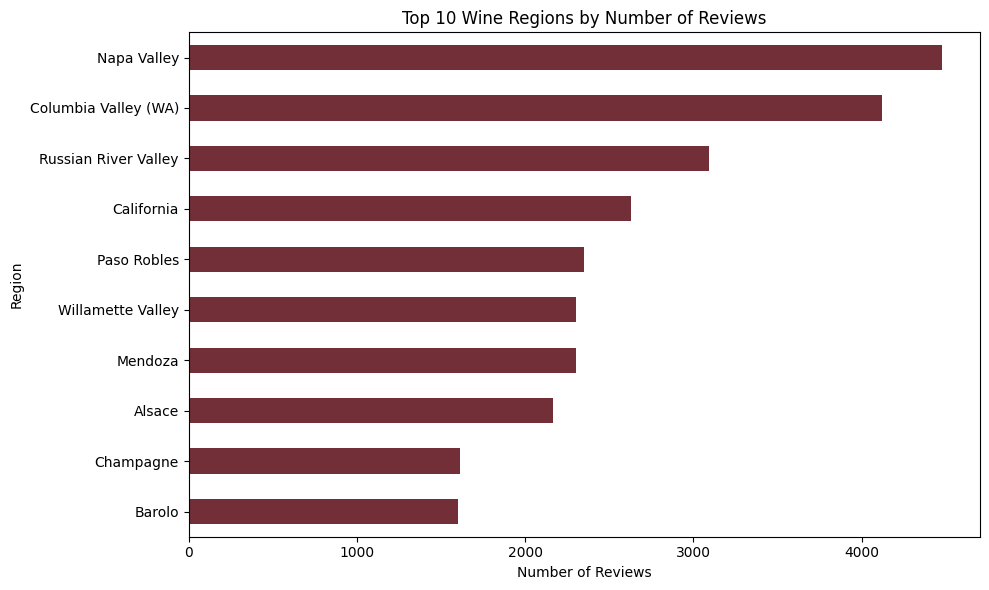

In [3]:
# Visualize the ten regions with the most reviews.
top_regions = region_counts.head(10).sort_values()

ax = top_regions.plot(kind='barh', figsize=(10, 6), color='#722F37')
ax.set_title('Top 10 Wine Regions by Number of Reviews')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Region')
plt.tight_layout()
plt.show()

### Filtering and target variable

- Focus on **Napa Valley** (`region_1`).
- target variable: `points`

In [4]:
# Keep only Napa Valley reviews for score EDA.
napa_reviews = reviews.loc[reviews['region_1'].eq('Napa Valley')].copy()

score_summary = napa_reviews['points'].describe().to_frame(name='Napa Valley scores')
score_summary.loc['high_score_rate (90+)'] = (napa_reviews['points'] >= 90).mean()

display(score_summary.round(2))
print(f"Napa Valley reviews: {len(napa_reviews):,}")
print(f"Share rated 90 or higher: {(napa_reviews['points'] >= 90).mean():.1%}")

,Napa Valley scores
count,4480.00
mean,89.04
std,3.19
min,80.00
25%,87.00
50%,89.00
75%,91.00
max,100.00
high_score_rate (90+),0.49


Napa Valley reviews: 4,480
Share rated 90 or higher: 49.1%


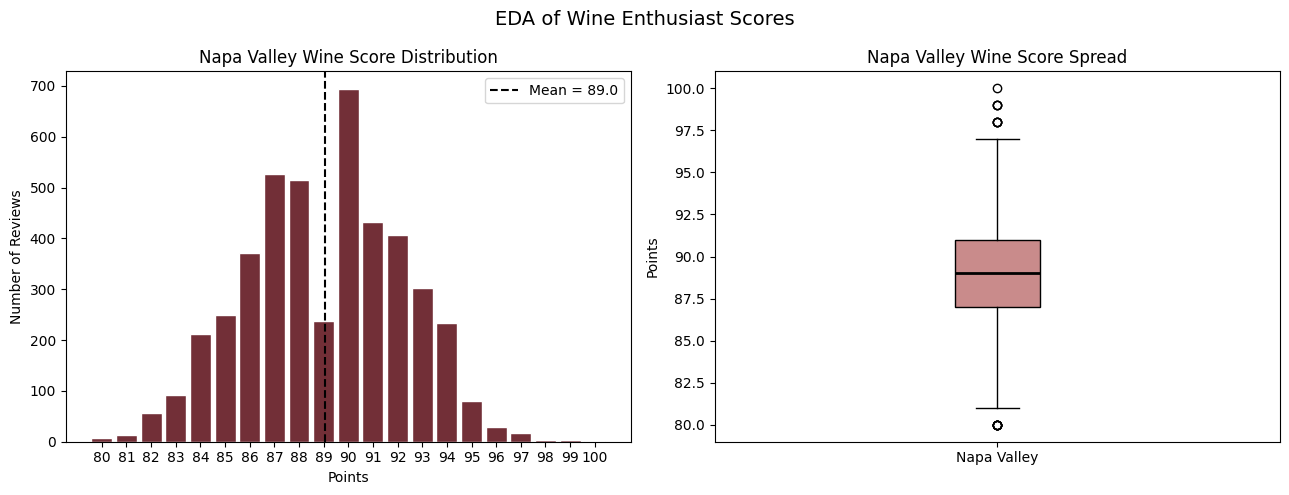

In [5]:
# Score distribution and spread for Napa Valley wines.
scores = napa_reviews['points']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(scores, bins=range(scores.min(), scores.max() + 2),
             align='left', rwidth=0.85, color='#722F37', edgecolor='white')
axes[0].axvline(scores.mean(), color='black', linestyle='--',
                label=f'Mean = {scores.mean():.1f}')
axes[0].set_title('Napa Valley Wine Score Distribution')
axes[0].set_xlabel('Points')
axes[0].set_ylabel('Number of Reviews')
axes[0].set_xticks(range(scores.min(), scores.max() + 1))
axes[0].legend()

axes[1].boxplot(scores, patch_artist=True,
                boxprops=dict(facecolor='#C98B8B'),
                medianprops=dict(color='black', linewidth=2))
axes[1].set_title('Napa Valley Wine Score Spread')
axes[1].set_ylabel('Points')
axes[1].set_xticks([1], ['Napa Valley'])

fig.suptitle('EDA of Wine Enthusiast Scores', fontsize=14)
plt.tight_layout()
plt.show()

## Paso Robles Team: Score Modeling Through Time

For the Paso Robles assignment, `points` is our target variable. We begin with Napa Valley reviews and use the vintage embedded in `title` as a proxy for the order in which review batches arrive. Models use **review text only**; vintage is used only to define the chronological train/test splits.

Chronological modeling sample: 4,139 unique Napa reviews


,mean_score,median_score,std_score,review_count
vintage,,,,
1992,90.00,90.0,NaN,1
1993,93.00,93.0,NaN,1
1994,90.00,90.0,0.00,2
1996,88.57,88.0,3.31,7
1997,90.99,91.0,2.00,72
1998,88.81,88.0,3.36,27
1999,89.80,90.0,3.24,49
2000,87.60,87.0,3.14,43
2001,88.90,89.5,3.19,20


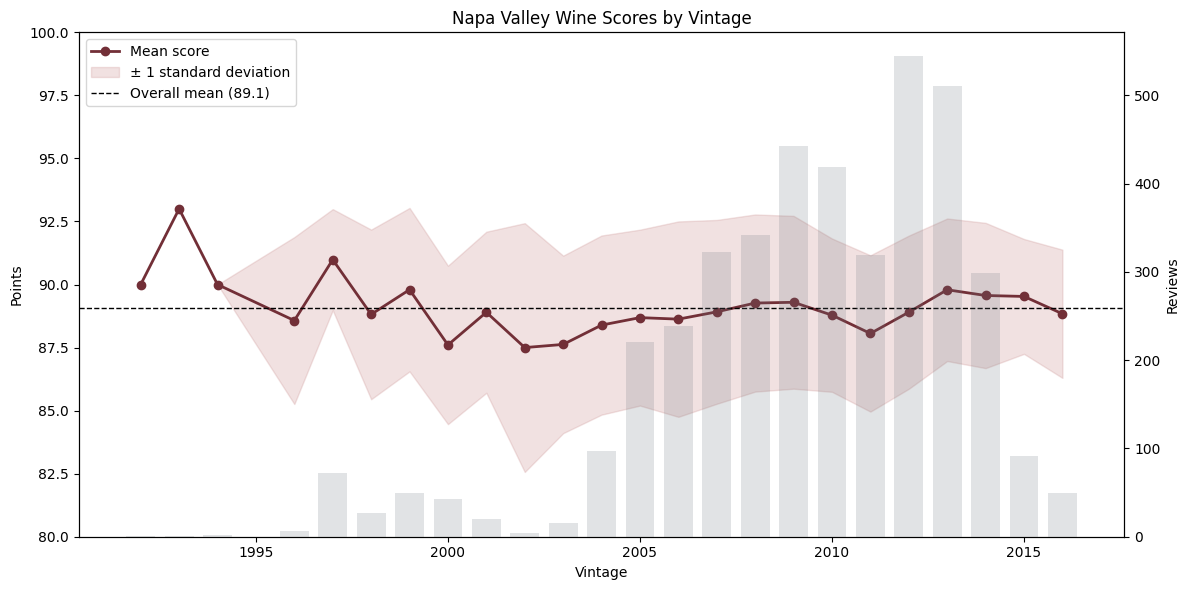

In [6]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
import warnings

# Vintage is not a supplied column, so extract a four-digit year from the title.
napa_time = napa_reviews[['title', 'description', 'points']].copy()
napa_time['vintage'] = pd.to_numeric(
    napa_time['title'].str.extract(r'\b((?:19|20)\d{2})\b', expand=False),
    errors='coerce'
)
# Retain reviews usable for text modeling and remove exact title/review repeats.
napa_time = (napa_time.dropna(subset=['vintage', 'description', 'points'])
                       .drop_duplicates(subset=['title', 'description'])
                       .sort_values('vintage')
                       .reset_index(drop=True))
napa_time['vintage'] = napa_time['vintage'].astype(int)

yearly_scores = napa_time.groupby('vintage')['points'].agg(
    mean_score='mean', median_score='median', std_score='std', review_count='size'
)
print(f'Chronological modeling sample: {len(napa_time):,} unique Napa reviews')
display(yearly_scores.round(2))

# Time plot: score trend plus review count, so sparse years are visible.
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(yearly_scores.index, yearly_scores['mean_score'], marker='o', color='#722F37',
         linewidth=2, label='Mean score')
ax1.fill_between(yearly_scores.index, yearly_scores['mean_score'] - yearly_scores['std_score'],
                 yearly_scores['mean_score'] + yearly_scores['std_score'],
                 color='#C98B8B', alpha=.25, label='± 1 standard deviation')
ax1.axhline(napa_time['points'].mean(), color='black', linestyle='--', linewidth=1,
            label=f"Overall mean ({napa_time['points'].mean():.1f})")
ax1.set(title='Napa Valley Wine Scores by Vintage', xlabel='Vintage', ylabel='Points', ylim=(80, 100))
ax1.legend(loc='upper left')
ax2 = ax1.twinx()
ax2.bar(yearly_scores.index, yearly_scores['review_count'], color='#6C757D', alpha=.20, width=.75)
ax2.set_ylabel('Reviews')
ax2.grid(False)
plt.tight_layout()
plt.show()

### Chronological training and evaluation

For each adequately sized test vintage, the training data includes only earlier vintages. This simulates receiving a new vintage batch in the future. We compare a historical-mean baseline with regularized TF-IDF Ridge regressions. MAE is easiest to interpret because it is measured in score points.

In [7]:
def make_text_model(ngrams):
    return make_pipeline(
        TfidfVectorizer(stop_words='english', min_df=2, ngram_range=ngrams,
                        max_features=25_000, sublinear_tf=True),
        Ridge(alpha=10.0, solver='lsqr', random_state=4401)
    )

vintage_counts = napa_time['vintage'].value_counts()
test_vintages = [year for year in sorted(vintage_counts.index)
                 if vintage_counts[year] >= 100 and (napa_time['vintage'] < year).sum() >= 500]
model_builders = {
    'Historical-mean baseline': lambda: DummyRegressor(strategy='mean'),
    'TF-IDF unigram Ridge': lambda: make_text_model((1, 1)),
    'TF-IDF 1–2 gram Ridge': lambda: make_text_model((1, 2)),
}

model_rows = []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
    for test_year in test_vintages:
        train = napa_time[napa_time['vintage'] < test_year]
        test = napa_time[napa_time['vintage'] == test_year]
        for model_name, build_model in model_builders.items():
            model = build_model()
            model.fit(train['description'], train['points'])
            predicted = model.predict(test['description'])
            model_rows.append({
                'test_vintage': test_year, 'model': model_name,
                'train_n': len(train), 'test_n': len(test),
                'MAE': mean_absolute_error(test['points'], predicted),
                'RMSE': mean_squared_error(test['points'], predicted) ** .5,
                'R2': r2_score(test['points'], predicted)
            })

chronological_results = pd.DataFrame(model_rows)
display(chronological_results.round(3))
print('Mean performance across chronological next-vintage tests:')
display(chronological_results.groupby('model')[['MAE', 'RMSE', 'R2']].mean().round(3))

,test_vintage,model,train_n,test_n,MAE,RMSE,R2
0,2006,Historical-mean baseline,560,239,3.346,3.878,-0.006
1,2006,TF-IDF unigram Ridge,560,239,2.875,3.354,0.247
2,2006,TF-IDF 1–2 gram Ridge,560,239,2.971,3.457,0.200
3,2007,Historical-mean baseline,799,323,3.097,3.640,-0.000
4,2007,TF-IDF unigram Ridge,799,323,2.488,2.963,0.337
5,2007,TF-IDF 1–2 gram Ridge,799,323,2.604,3.085,0.281
6,2008,Historical-mean baseline,1122,342,2.982,3.529,-0.013
7,2008,TF-IDF unigram Ridge,1122,342,2.230,2.731,0.393
8,2008,TF-IDF 1–2 gram Ridge,1122,342,2.382,2.875,0.328
9,2009,Historical-mean baseline,1464,443,2.902,3.439,-0.010


Mean performance across chronological next-vintage tests:


,MAE,RMSE,R2
model,,,
Historical-mean baseline,2.778,3.299,-0.030
TF-IDF 1–2 gram Ridge,2.272,2.728,0.297
TF-IDF unigram Ridge,2.168,2.621,0.350


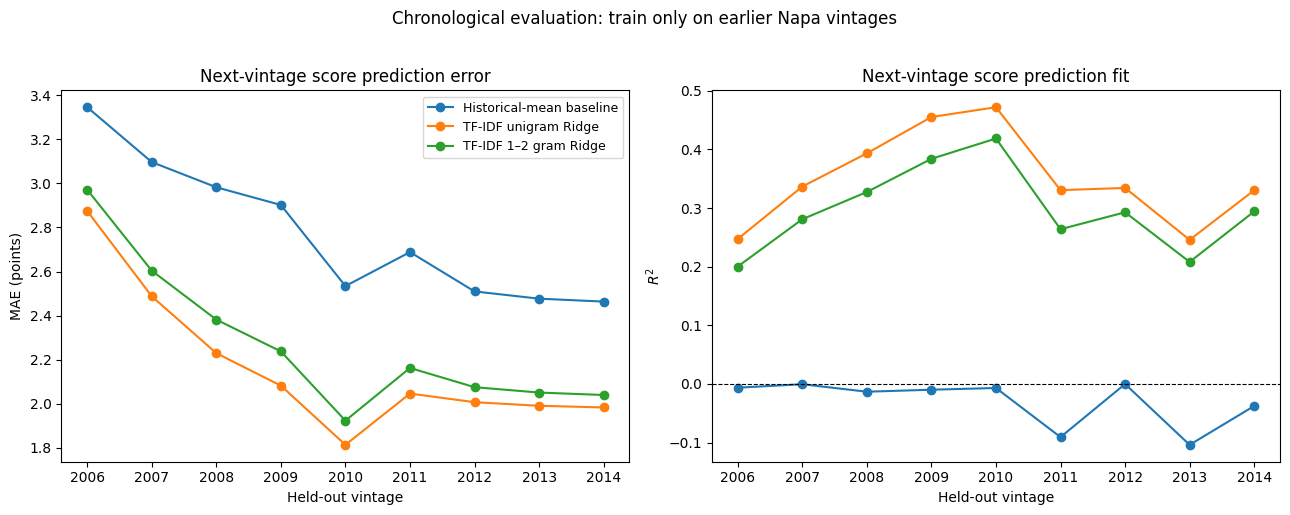

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, group in chronological_results.groupby('model', sort=False):
    axes[0].plot(group['test_vintage'], group['MAE'], marker='o', label=model_name)
    axes[1].plot(group['test_vintage'], group['R2'], marker='o', label=model_name)
axes[0].set(title='Next-vintage score prediction error', xlabel='Held-out vintage', ylabel='MAE (points)')
axes[1].set(title='Next-vintage score prediction fit', xlabel='Held-out vintage', ylabel='$R^2$')
axes[1].axhline(0, color='black', linewidth=.8, linestyle='--')
axes[0].legend(fontsize=9)
fig.suptitle('Chronological evaluation: train only on earlier Napa vintages', y=1.02)
plt.tight_layout()
plt.show()

### Review-language evolution and score interpretation

The first table identifies review terms most associated with predicted score in the final regularized model. The second compares average TF-IDF usage in earlier (1997–2006) versus later (2010–2014) well-sampled vintages. These are associations, not causal claims.

In [9]:
# Interpretable score-language associations from all Napa review text.
score_vectorizer = TfidfVectorizer(stop_words='english', min_df=3, max_features=15_000, sublinear_tf=True)
X_score = score_vectorizer.fit_transform(napa_time['description'])
score_ridge = Ridge(alpha=10.0, solver='lsqr', random_state=4401)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
    score_ridge.fit(X_score, napa_time['points'])
score_terms = pd.DataFrame({
    'term': score_vectorizer.get_feature_names_out(),
    'coefficient': score_ridge.coef_
})
high_score_terms = score_terms.nlargest(15, 'coefficient').assign(association='higher predicted score')
low_score_terms = score_terms.nsmallest(15, 'coefficient').assign(association='lower predicted score')
display(pd.concat([high_score_terms, low_score_terms], ignore_index=True).round(3))

# Describe language shift without using target-score information.
early_reviews = napa_time.query('1997 <= vintage <= 2006')
late_reviews = napa_time.query('2010 <= vintage <= 2014')
shift_vectorizer = TfidfVectorizer(stop_words='english', min_df=5, max_features=10_000, sublinear_tf=True)
X_shift = shift_vectorizer.fit_transform(pd.concat([early_reviews['description'], late_reviews['description']]))
early_mean = np.asarray(X_shift[:len(early_reviews)].mean(axis=0)).ravel()
late_mean = np.asarray(X_shift[len(early_reviews):].mean(axis=0)).ravel()
language_shift = pd.DataFrame({
    'term': shift_vectorizer.get_feature_names_out(),
    'early_mean_tfidf': early_mean, 'late_mean_tfidf': late_mean
})
language_shift['late_minus_early'] = language_shift['late_mean_tfidf'] - language_shift['early_mean_tfidf']
more_late = language_shift.nlargest(15, 'late_minus_early').assign(period='more characteristic of 2010–2014')
more_early = language_shift.nsmallest(15, 'late_minus_early').assign(period='more characteristic of 1997–2006')
display(pd.concat([more_late, more_early], ignore_index=True).round(3))

,term,coefficient,association
0,years,3.863,higher predicted score
1,complex,3.711,higher predicted score
2,beautiful,3.274,higher predicted score
3,long,2.997,higher predicted score
4,great,2.715,higher predicted score
5,cassis,2.638,higher predicted score
6,vineyard,2.615,higher predicted score
7,delicious,2.493,higher predicted score
8,refined,2.471,higher predicted score
9,cellar,2.465,higher predicted score


,term,early_mean_tfidf,late_mean_tfidf,late_minus_early,period
0,bodied,0.004,0.027,0.023,more characteristic of 2010–2014
1,sauvignon,0.008,0.028,0.020,more characteristic of 2010–2014
2,verdot,0.000,0.018,0.017,more characteristic of 2010–2014
3,petit,0.000,0.018,0.017,more characteristic of 2010–2014
4,tannin,0.002,0.019,0.016,more characteristic of 2010–2014
5,juicy,0.002,0.017,0.015,more characteristic of 2010–2014
6,cabernet,0.022,0.037,0.015,more characteristic of 2010–2014
7,clove,0.000,0.014,0.014,more characteristic of 2010–2014
8,offers,0.003,0.016,0.013,more characteristic of 2010–2014
9,franc,0.004,0.017,0.013,more characteristic of 2010–2014
